# Étape 3 : Preprocessing sans fuite de données

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Pilier évalué :** n° 2, *data preprocessing & leakage prevention*.

Cette étape prépare les données des deux modèles supervisés, sans entraîner de modèle final :

| Jeu | Utilisé à | Cible | Lignes |
|---|---|---|---|
| **A. Classification** | étape 5 | `pha` (objet potentiellement dangereux) | tout le catalogue |
| **B. Régression** | étape 4 | log10 du diamètre | uniquement les diamètres **mesurés** |

Les règles appliquées, dans cet ordre :

1. **Inventorier chaque colonne** et décider explicitement si elle peut servir de variable.
2. **Séparer train et test avant tout calcul statistique** (moyenne, médiane, écart-type).
3. **Mettre l'imputation, la mise à l'échelle et l'encodage dans un `Pipeline`** scikit-learn, pour qu'ils soient ajustés sur le train uniquement, y compris à l'intérieur de chaque pli de validation croisée.
4. **Auditer la fuite** en comparant un modèle avec et sans les variables interdites.

In [2]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

set_config(display="diagram")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
TEST_SIZE = 0.20

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "03_preprocessing"   # non versionné
REPORT_DIR = PROJECT_DIR / "reports" / "03_preprocessing"                # versionné
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREY, RED = "#2878B5", "#E07A2D", "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
asteroids["first_obs_year"] = pd.to_datetime(asteroids["first_obs"], errors="coerce").dt.year
print(f"Catalogue : {fmt(len(asteroids))} objets × {asteroids.shape[1]} colonnes")

Catalogue : 41 281 objets × 30 colonnes


## 1. Inventaire des colonnes : qui a le droit d'être une variable ?

Chaque colonne reçoit un **rôle** et une **justification**. Ce tableau est la preuve écrite des choix de variables pour la slide 4.

Les catégories de rejet :

- **Fuite directe** : la colonne entre dans la définition de la cible (`pha` = MOID ≤ 0,05 UA et H ≤ 22).
- **Dérivée de H** : la colonne est calculée à partir de H, c'est donc H sous un autre nom.
- **Non disponible** : la colonne manque pour la grande majorité des objets.
- **Redondante** : la colonne est une transformation exacte d'une autre déjà retenue.

In [3]:
inventory = pd.DataFrame([
    # colonne, rôle, justification
    ("spkid / pdes / full_name / name", "identifiant", "Aucune information physique"),
    ("pha", "cible (jeu A)", "Label à prédire"),
    ("moid_au / moid_km / moid_lunar_distances", "exclue : fuite directe", "Seuil MOID ≤ 0,05 UA de la définition de pha"),
    ("H", "exclue : fuite directe (jeu A)", "Seuil H ≤ 22 de la définition de pha ; autorisée pour le jeu B"),
    ("diameter_km / diameter_m", "exclue : dérivée de H (jeu A) ; cible (jeu B)", "97 % calculés à partir de H avec albédo 0,14"),
    ("diameter_is_estimated", "filtre (jeu B)", "Sert à ne garder que les diamètres mesurés"),
    ("size_category", "exclue : dérivée de H", "Découpage du diamètre, donc de H"),
    ("albedo", "exclue : non disponible", "Manque pour 97 % des objets ; donne le diamètre presque exactement avec H"),
    ("rot_per", "exclue : non disponible", "Manque pour 95 % des objets"),
    ("a / e / i / q / ad", "retenue (orbite)", "Éléments orbitaux, connus pour 100 % des objets"),
    ("class", "retenue (orbite, catégorielle)", "Famille orbitale (Apollo, Amor, Aten, Atira)"),
    ("per / per_y / n", "exclue : redondante", "Fonctions de a (3e loi de Kepler)"),
    ("condition_code / data_arc_years / first_obs_year", "variante : proxy de taille", "Disponibles, mais liées à la taille par le biais de détection (voir section 2)"),
    ("data_arc / first_obs / last_obs", "exclue : redondante", "Mêmes informations que data_arc_years et first_obs_year"),
], columns=["colonne(s)", "rôle", "justification"])
inventory.to_csv(REPORT_DIR / "inventaire_variables.csv", index=False)
inventory

,colonne(s),rôle,justification
0,spkid / pdes / full_name / name,identifiant,Aucune information physique
1,pha,cible (jeu A),Label à prédire
2,moid_au / moid_km / moid_lunar_distances,exclue : fuite directe,"Seuil MOID ≤ 0,05 UA de la définition de pha"
3,H,exclue : fuite directe (jeu A),Seuil H ≤ 22 de la définition de pha ; autoris...
4,diameter_km / diameter_m,exclue : dérivée de H (jeu A) ; cible (jeu B),"97 % calculés à partir de H avec albédo 0,14"
5,diameter_is_estimated,filtre (jeu B),Sert à ne garder que les diamètres mesurés
6,size_category,exclue : dérivée de H,"Découpage du diamètre, donc de H"
7,albedo,exclue : non disponible,Manque pour 97 % des objets ; donne le diamètr...
8,rot_per,exclue : non disponible,Manque pour 95 % des objets
9,a / e / i / q / ad,retenue (orbite),"Éléments orbitaux, connus pour 100 % des objets"


## 2. Détecter les proxys : quelles variables « savent » la taille ?

Une variable peut ne pas entrer dans la définition de `pha` et pourtant contenir la même information. On mesure la corrélation de rang (Spearman) de chaque candidate avec **H** et avec le **MOID**, les deux variables interdites.

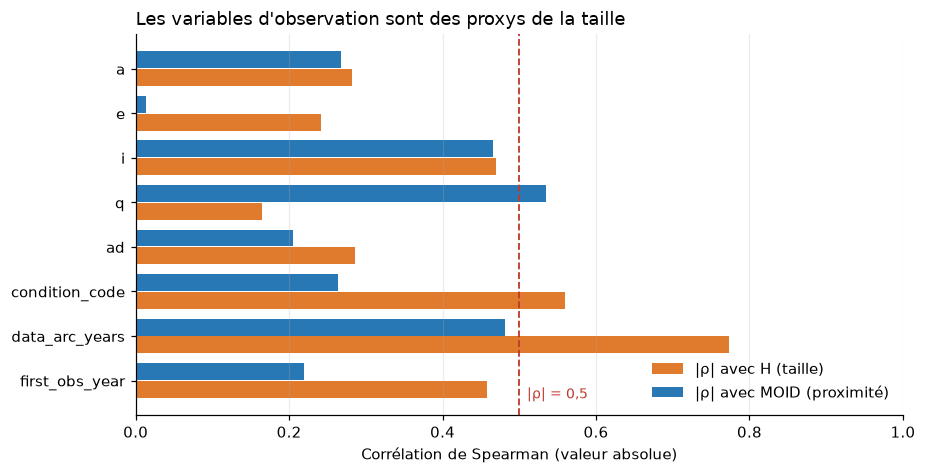

,H,moid_au
a,-0.280,0.270
e,-0.240,-0.010
i,-0.470,0.470
q,-0.160,0.540
ad,-0.290,0.200
condition_code,0.560,-0.260
data_arc_years,-0.770,0.480
first_obs_year,0.460,-0.220


In [6]:
ORBITAL_NUM = ["a", "e", "i", "q", "ad"]
ORBITAL_CAT = ["class"]
OBSERVATION_NUM = ["condition_code", "data_arc_years", "first_obs_year"]

candidates = ORBITAL_NUM + OBSERVATION_NUM
corr = asteroids[candidates + ["H", "moid_au"]].corr(method="spearman").loc[candidates, ["H", "moid_au"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(candidates))
ax.barh(y + 0.2, corr["H"].abs(), height=0.38, color=ORANGE, label="|ρ| avec H (taille)")
ax.barh(y - 0.2, corr["moid_au"].abs(), height=0.38, color=BLUE, label="|ρ| avec MOID (proximité)")
ax.set_yticks(y, candidates)
ax.invert_yaxis()
ax.axvline(0.5, color=RED, ls="--", lw=1.2)
ax.text(0.51, len(candidates) - 0.6, "|ρ| = 0,5", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 1)
ax.set_xlabel("Corrélation de Spearman (valeur absolue)")
ax.set_title("Les variables d'observation sont des proxys de la taille", loc="left")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "proxys_taille_proximite")
plt.show()

corr.round(2).to_csv(REPORT_DIR / "correlations_proxys.csv")
corr.round(2)

**Lecture :**

- `data_arc_years` (durée pendant laquelle l'objet a été observé) a une corrélation de **−0,77** avec H. Les gros objets sont plus brillants, donc découverts plus tôt et suivis plus longtemps. Cette variable « connaît » donc la taille.
- `condition_code` (incertitude de l'orbite, de 0 à 9) et `first_obs_year` (année de découverte) suivent la même logique, avec une corrélation d'environ 0,5.
- Les éléments orbitaux restent modérément corrélés au MOID (q : 0,54). C'est attendu et légitime : l'orbite détermine physiquement la proximité avec la Terre. Ce n'est pas une copie de la cible.

**Décision :** deux jeux de variables seront comparés à l'étape 5.

- **Orbite** (référence) : `a, e, i, q, ad, class`. Aucune fuite, aucun proxy.
- **Orbite + observation** (variante) : on ajoute `condition_code, data_arc_years, first_obs_year`. Ces variables sont disponibles au moment de la décision, mais une partie de leur performance viendra de la taille, apprise indirectement. Il faudra l'annoncer clairement.

## 3. Jeu A : séparation train / test pour la classification

La séparation se fait **en premier**, avant tout calcul de moyenne, de médiane ou d'écart-type. Elle est **stratifiée** pour conserver la même proportion de PHA (6,2 %) des deux côtés.

In [7]:
FEATURES_ORBIT = ORBITAL_NUM + ORBITAL_CAT
FEATURES_ORBIT_OBS = ORBITAL_NUM + OBSERVATION_NUM + ORBITAL_CAT
LEAKY_FEATURES = ["H", "moid_au"]   # uniquement pour l'audit de fuite, jamais pour le modèle
TARGET = "pha"

keep = ["pdes", TARGET] + ORBITAL_NUM + OBSERVATION_NUM + ORBITAL_CAT + LEAKY_FEATURES
data_A = asteroids[keep].copy()

train_A, test_A = train_test_split(
    data_A, test_size=TEST_SIZE, stratify=data_A[TARGET], random_state=RANDOM_STATE)

split_check = pd.DataFrame({
    "lignes": [len(data_A), len(train_A), len(test_A)],
    "PHA": [data_A[TARGET].sum(), train_A[TARGET].sum(), test_A[TARGET].sum()],
    "% PHA": [data_A[TARGET].mean() * 100, train_A[TARGET].mean() * 100, test_A[TARGET].mean() * 100],
}, index=["Catalogue", "Train (80 %)", "Test (20 %)"])
split_check.to_csv(REPORT_DIR / "split_classification.csv")
split_check

,lignes,PHA,% PHA
Catalogue,41281,2539,6.151
Train (80 %),33024,2031,6.150
Test (20 %),8257,508,6.152


## 4. Le pipeline de preprocessing

- **Variables numériques** : imputation par la médiane, puis standardisation. Les arbres n'en ont pas besoin, mais le clustering et les modèles linéaires, si.
- **Variables très asymétriques** (`a`, `ad`, `data_arc_years`) : passage au logarithme (`log1p`, qui accepte les zéros de `data_arc_years`) avant la standardisation. Quelques objets ont un demi-grand axe de plusieurs dizaines d'UA ; sans le logarithme, ils écrasent l'échelle de tous les autres.
- **Variable catégorielle** (`class`) : encodage one-hot. `handle_unknown="ignore"` évite une erreur si une famille absente du train apparaît dans le test.

Le préprocesseur est **défini** ici mais **jamais ajusté sur l'ensemble des données**. Il est placé dans un `Pipeline` avec le modèle, ce qui garantit que `fit` ne voit que les données d'entraînement.

In [8]:
SKEWED = ["a", "ad", "data_arc_years"]   # strictement positives, très étalées

def make_preprocessor(numeric: list[str], categorical: list[str]) -> ColumnTransformer:
    skewed = [c for c in numeric if c in SKEWED]
    regular = [c for c in numeric if c not in SKEWED]
    transformers = []
    if regular:
        transformers.append(("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), regular))
    if skewed:
        transformers.append(("num_log", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scaler", StandardScaler()),
        ]), skewed))
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

preprocessor_orbit = make_preprocessor(ORBITAL_NUM, ORBITAL_CAT)
preprocessor_orbit_obs = make_preprocessor(ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT)
preprocessor_orbit

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('num_log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transfo

### Preuve que le test n'a pas servi à l'ajustement

On ajuste le préprocesseur **sur le train seul**, puis on l'applique au test. Après standardisation, le train a exactement une moyenne de 0 et un écart-type de 1. Le test, lui, s'en écarte légèrement : ses statistiques n'ont pas été utilisées. Si le scaler avait été ajusté avant la séparation, les deux seraient identiques.

In [9]:
demo = make_preprocessor(ORBITAL_NUM, ORBITAL_CAT).fit(train_A[FEATURES_ORBIT])
Xtr = pd.DataFrame(demo.transform(train_A[FEATURES_ORBIT]), columns=demo.get_feature_names_out())
Xte = pd.DataFrame(demo.transform(test_A[FEATURES_ORBIT]), columns=demo.get_feature_names_out())

proof = pd.DataFrame({
    "moyenne train": Xtr[ORBITAL_NUM].mean(),
    "écart-type train": Xtr[ORBITAL_NUM].std(ddof=0),
    "moyenne test": Xte[ORBITAL_NUM].mean(),
    "écart-type test": Xte[ORBITAL_NUM].std(ddof=0),
})
proof.to_csv(REPORT_DIR / "preuve_scaler_train_only.csv")
print("Variables produites :", list(demo.get_feature_names_out()))
proof.round(4)

Variables produites : ['e', 'i', 'q', 'a', 'ad', 'class_AMO', 'class_APO', 'class_ATE', 'class_IEO']


,moyenne train,écart-type train,moyenne test,écart-type test
a,0.000,1.000,-0.009,0.973
e,0.000,1.000,0.015,1.013
i,-0.000,1.000,0.019,0.992
q,-0.000,1.000,-0.030,1.019
ad,-0.000,1.000,-0.003,0.986


## 5. Audit de fuite

On compare trois jeux de variables avec le **même modèle** (Random Forest, `class_weight="balanced"`) et la **même validation croisée stratifiée à 5 plis**, calculée **sur le train uniquement** : le test reste intact pour l'étape 5.

Le préprocesseur est à l'intérieur du `Pipeline`. Il est donc réajusté dans chaque pli, sur les 4/5 d'entraînement de ce pli.

La métrique principale est la **PR-AUC** (aire sous la courbe précision/rappel). Un modèle qui tire au hasard obtient la proportion de PHA, soit **0,06**.

In [10]:
def audit_model(numeric, categorical):
    return Pipeline([
        ("prep", make_preprocessor(numeric, categorical)),
        ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                         class_weight="balanced", n_jobs=-1,
                                         random_state=RANDOM_STATE)),
    ])

feature_sets = {
    "Interdit : H + MOID": (LEAKY_FEATURES, []),
    "Orbite": (ORBITAL_NUM, ORBITAL_CAT),
    "Orbite + observation": (ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for name, (num, cat) in feature_sets.items():
    scores = cross_validate(audit_model(num, cat), train_A[num + cat], train_A[TARGET], cv=cv,
                            scoring={"rappel": "recall", "précision": "precision",
                                     "F1": "f1", "PR-AUC": "average_precision"})
    rows.append({"jeu de variables": name,
                 **{m: scores[f"test_{m}"].mean() for m in ["rappel", "précision", "F1", "PR-AUC"]}})

audit = pd.DataFrame(rows).set_index("jeu de variables")
audit.to_csv(REPORT_DIR / "audit_fuite.csv")
audit.round(3)

,rappel,précision,F1,PR-AUC
jeu de variables,,,,
Interdit : H + MOID,0.992,0.948,0.970,0.998
Orbite,0.409,0.152,0.222,0.147
Orbite + observation,0.850,0.329,0.475,0.475


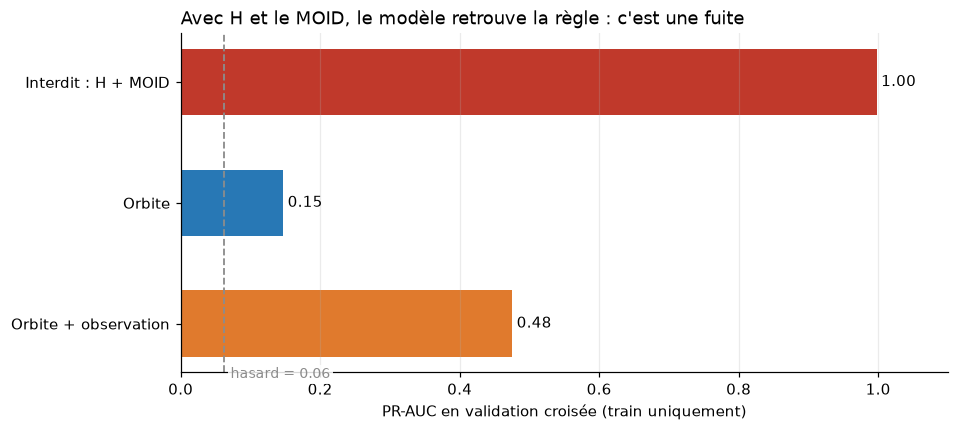

In [11]:
chance = train_A[TARGET].mean()
fig, ax = plt.subplots(figsize=(9, 4))
colors = [RED, BLUE, ORANGE]
bars = ax.barh(audit.index[::-1], audit["PR-AUC"][::-1], color=colors[::-1], height=0.55)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in audit["PR-AUC"][::-1]], padding=3)
ax.axvline(chance, color=GREY, ls="--", lw=1.2)
ax.text(chance + 0.01, -0.45, f"hasard = {chance:.2f}", color=GREY, fontsize=9, bbox=LABEL_BOX)
ax.set_xlim(0, 1.1)
ax.set_xlabel("PR-AUC en validation croisée (train uniquement)")
ax.set_title("Avec H et le MOID, le modèle retrouve la règle : c'est une fuite", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "audit_fuite_pr_auc")
plt.show()

**Lecture :**

- **H + MOID** : PR-AUC proche de 1. Le modèle retrouve la règle officielle. C'est un score parfait qui ne prouve rien, et c'est exactement le piège évité.
- **Orbite seule** : le signal est réel (nettement au-dessus du hasard) mais modeste. C'est la réponse honnête à la question « peut-on repérer un objet dangereux à partir de son orbite seule ? ». L'orbite indique si l'objet *peut* passer près, mais pas s'il est *assez gros*.
- **Orbite + observation** : bien meilleur, mais une partie du gain vient de la taille apprise indirectement via `data_arc_years` (section 2).

**Ce que ça implique pour l'étape 5 :** le modèle « orbite » sert de référence sans fuite, et le modèle « orbite + observation » est présenté comme une variante, avec sa limite. Le seuil de décision sera ensuite abaissé pour viser le rappel maximal demandé par la PDCO, en mesurant la précision perdue.

## 6. Jeu B : régression du diamètre (préparation de l'étape 4)

On ne garde que les objets dont le diamètre est **réellement mesuré**. Les diamètres estimés sont la formule appliquée à H : les utiliser comme cible donnerait un R² ≈ 1 sans intérêt.

- **Cible** : log10 du diamètre en km. Les diamètres vont de quelques mètres à plusieurs dizaines de km ; le logarithme rend les erreurs relatives comparables d'un bout à l'autre.
- **Variables** : H (autorisé ici, car la cible n'est plus `pha`) + éléments orbitaux + famille.
- **Exclu : l'albédo.** Avec H et l'albédo, la formule physique redonne le diamètre presque exactement. Surtout, l'albédo manque pour 97 % du catalogue : un modèle qui en dépend ne pourrait pas être appliqué aux objets dont on veut justement estimer la taille.

In [13]:
measured = asteroids[~asteroids["diameter_is_estimated"]].dropna(subset=["H", "diameter_km"]).copy()
with_albedo = measured.dropna(subset=["albedo"])
formula = 1329 / np.sqrt(with_albedo["albedo"]) * 10 ** (-with_albedo["H"] / 5)
ratio = formula / with_albedo["diameter_km"]
print(f"Objets avec diamètre mesuré : {fmt(len(measured))}")
print(f"Avec l'albédo réel, la formule donne le diamètre à ±{(ratio - 1).abs().median():.1%} près (médiane) "
      f"→ l'albédo serait une fuite.")

FEATURES_DIAMETER_NUM = ["H"] + ORBITAL_NUM
FEATURES_DIAMETER_CAT = ORBITAL_CAT
TARGET_DIAMETER = "log10_diameter_km"

data_B = measured[["pdes", "diameter_km"] + FEATURES_DIAMETER_NUM + FEATURES_DIAMETER_CAT].copy()
data_B[TARGET_DIAMETER] = np.log10(data_B["diameter_km"])

# Stratification sur les quintiles de la cible pour garder la même gamme de tailles des deux côtés
size_bins = pd.qcut(data_B[TARGET_DIAMETER], q=5, labels=False)
train_B, test_B = train_test_split(data_B, test_size=TEST_SIZE, stratify=size_bins,
                                   random_state=RANDOM_STATE)
print(f"Train : {fmt(len(train_B))} | Test : {fmt(len(test_B))}")

Objets avec diamètre mesuré : 1 244
Avec l'albédo réel, la formule donne le diamètre à ±4.5% près (médiane) → l'albédo serait une fuite.
Train : 995 | Test : 249


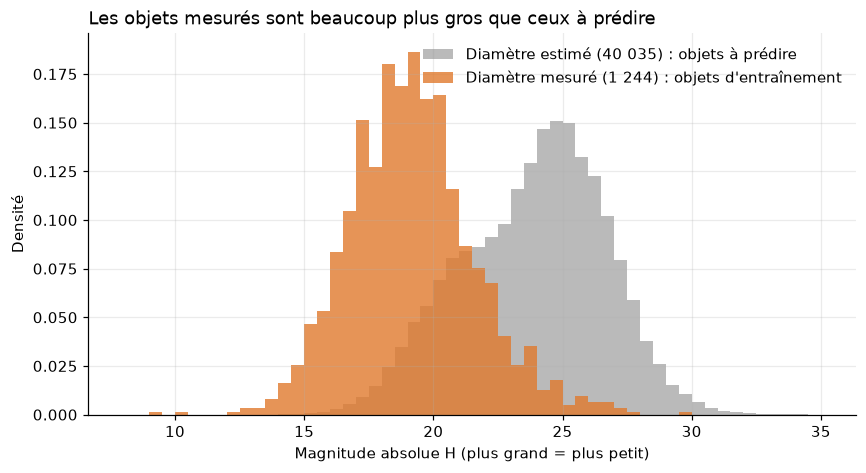

H médian : mesurés 19.1 | estimés 24.1
Objets avec H > 24 (moins de ~50 m) : 3.1% des mesurés (38 objets), contre 51.7% des objets à prédire


In [14]:
estimated = asteroids[asteroids["diameter_is_estimated"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(8, 35, 55)
ax.hist(estimated["H"], bins=bins, density=True, color=GREY, alpha=0.6,
        label=f"Diamètre estimé ({fmt(len(estimated))}) : objets à prédire")
ax.hist(measured["H"], bins=bins, density=True, color=ORANGE, alpha=0.8,
        label=f"Diamètre mesuré ({fmt(len(measured))}) : objets d'entraînement")
ax.set_xlabel("Magnitude absolue H (plus grand = plus petit)")
ax.set_ylabel("Densité")
ax.set_title("Les objets mesurés sont beaucoup plus gros que ceux à prédire", loc="left")
ax.legend(frameon=False)
save(fig, "decalage_population_diametre")
plt.show()

print(f"H médian : mesurés {measured['H'].median():.1f} | estimés {estimated['H'].median():.1f}")
print(f"Objets avec H > 24 (moins de ~50 m) : {(measured['H'] > 24).mean():.1%} des mesurés "
      f"({fmt((measured['H'] > 24).sum())} objets), contre {(estimated['H'] > 24).mean():.1%} des objets à prédire")

**Limite à annoncer :** le modèle de l'étape 4 apprendra sur des objets surtout gros (H médian ≈ 19) et sera appliqué à des objets surtout petits (H médian ≈ 24). Il dispose de très peu d'exemples dans la zone des petits objets, où se trouve pourtant la moitié du catalogue. À l'étape 4, on évaluera l'erreur par tranche de H et on retombera sur la formule physique là où le modèle n'a pas de données.

## 7. Sauvegarde pour les étapes 4 et 5

In [15]:
train_A.to_csv(PROCESSED_DIR / "classification_train.csv", index=False)
test_A.to_csv(PROCESSED_DIR / "classification_test.csv", index=False)
train_B.to_csv(PROCESSED_DIR / "diameter_train.csv", index=False)
test_B.to_csv(PROCESSED_DIR / "diameter_test.csv", index=False)

# Préprocesseurs NON ajustés : ils seront ajustés dans le Pipeline de chaque modèle
joblib.dump(make_preprocessor(ORBITAL_NUM, ORBITAL_CAT), PROCESSED_DIR / "preprocessor_orbit.joblib")
joblib.dump(make_preprocessor(ORBITAL_NUM + OBSERVATION_NUM, ORBITAL_CAT), PROCESSED_DIR / "preprocessor_orbit_obs.joblib")
joblib.dump(make_preprocessor(FEATURES_DIAMETER_NUM, FEATURES_DIAMETER_CAT), PROCESSED_DIR / "preprocessor_diameter.joblib")

config = {
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "classification": {
        "target": TARGET,
        "features_orbit": {"numeric": ORBITAL_NUM, "categorical": ORBITAL_CAT},
        "features_orbit_obs": {"numeric": ORBITAL_NUM + OBSERVATION_NUM, "categorical": ORBITAL_CAT},
        "forbidden": ["H", "moid_au", "moid_km", "moid_lunar_distances", "diameter_km",
                      "diameter_m", "size_category", "albedo"],
    },
    "diameter_regression": {
        "target": TARGET_DIAMETER,
        "rows": "diameter_is_estimated == False",
        "features": {"numeric": FEATURES_DIAMETER_NUM, "categorical": FEATURES_DIAMETER_CAT},
        "forbidden": ["albedo", "diameter_m", "size_category"],
    },
}
(REPORT_DIR / "config_preprocessing.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

print("Données :", sorted(p.name for p in PROCESSED_DIR.iterdir()))
print("Rapports :", sorted(p.name for p in REPORT_DIR.iterdir()))

Données : ['classification_test.csv', 'classification_train.csv', 'diameter_test.csv', 'diameter_train.csv', 'preprocessor_diameter.joblib', 'preprocessor_orbit.joblib', 'preprocessor_orbit_obs.joblib']
Rapports : ['audit_fuite.csv', 'audit_fuite_pr_auc.png', 'config_preprocessing.json', 'correlations_proxys.csv', 'decalage_population_diametre.png', 'inventaire_variables.csv', 'preuve_scaler_train_only.csv', 'proxys_taille_proximite.png', 'split_classification.csv']


## Synthèse

| Règle anti-fuite | Mise en œuvre |
|---|---|
| Aucune variable qui définit la cible | MOID, H et toutes les colonnes dérivées de H exclus du jeu A (inventaire, section 1) |
| Aucun proxy caché sans le dire | Corrélations avec H et MOID mesurées ; variables d'observation isolées dans une variante (section 2) |
| Séparation avant tout calcul | `train_test_split` stratifié en premier (sections 3 et 6) |
| Préprocesseur ajusté sur le train seul | `ColumnTransformer` dans un `Pipeline`, réajusté dans chaque pli de validation croisée (sections 4 et 5) |
| Preuve chiffrée | Moyenne/écart-type train vs test (section 4) et audit H + MOID vs orbite (section 5) |
| Cible de régression non circulaire | Diamètres mesurés uniquement, albédo exclu (section 6) |

Pour les étapes suivantes, tout est chargé depuis `data/processed/03_preprocessing/` et `reports/03_preprocessing/config_preprocessing.json`. Ce notebook doit donc être exécuté avant les notebooks 04 et 05.